In [1]:
import scanpy as sc
import rapids_singlecell as rsc
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from tqdm import tqdm

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

from scatlastb_utils.io import read_anndata
from scatlastb_utils.pipeline.misc import dask_compute
from misc import plot_diff_per_clusters

/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cuda module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.driver module instead.
/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jup

# Read Data

In [2]:
adata = read_anndata(
    'data/output/qc/hlca_epithelial.zarr',
    X='X',
    obs='obs',
    var='var',
    obsm='obsm',
    uns='uns',
    obsp='obsp',
    dask_slots=['layers', 'X', 'obsp'],
    dask=True,
    backed=True,
)

AssertionError: File not found: data/output/qc/hlca_epithelial.zarr

In [ ]:
# remove too small clusters
cluster_cols = [col for col in adata.obs.columns if col.startswith('leiden')]
for col in tqdm(cluster_cols):
    for cluster, count in adata.obs[col].value_counts().items():
        if count < 10:
            adata.obs.loc[adata.obs[col] == cluster, col] = float('nan')
    adata.obs[col] = adata.obs[col].astype('category').cat.remove_unused_categories()

In [ ]:
# set colors
ref_key = 'manual_ann'
for col in tqdm([x for x in adata.obs.columns if x.startswith('majority_reference')]):
    adata.obs[col] = adata.obs[col].cat.set_categories(adata.obs[ref_key].cat.categories)

# Marker genes

In [ ]:
from marker_genes_functions import filter_marker_genes, extract_de_genes, update_marker_gene_keys

In [68]:
markers, gene_set = filter_marker_genes('configs/gene_sets.yaml', adata)

201 unique marker genes


In [69]:
genes_to_plot = extract_de_genes(adata) | gene_set

100%|██████████| 137/137 [02:19<00:00,  1.02s/it]


In [70]:
%%time
# subset to genes
adata = dask_compute(adata[:, adata.var_names.isin(genes_to_plot)].copy())

Apply function compute_layer to X...


Dask compute: 100%|██████████| 6/6 [00:08<00:00,  1.34s/it]

Apply function compute_layer to raw...
CPU times: user 41.6 s, sys: 2.98 s, total: 44.6 s
Wall time: 46.6 s


In [71]:
# needed for rank_genes_groups to correctly identify the precomputed groups
update_marker_gene_keys(adata)

100%|██████████| 135/135 [00:00<00:00, 1301680.55it/s]


In [72]:
cluster_key = f'leiden_0.5_1--{integration1}'
cluster_key = 'majority_reference'
# cluster_key = f'manual_ann--{integration1}'

/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 3690 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


categories: AT1, AT2, Arterial EC, etc.
var_group_labels: Epithelial, AT, pre-TB secretory, etc.


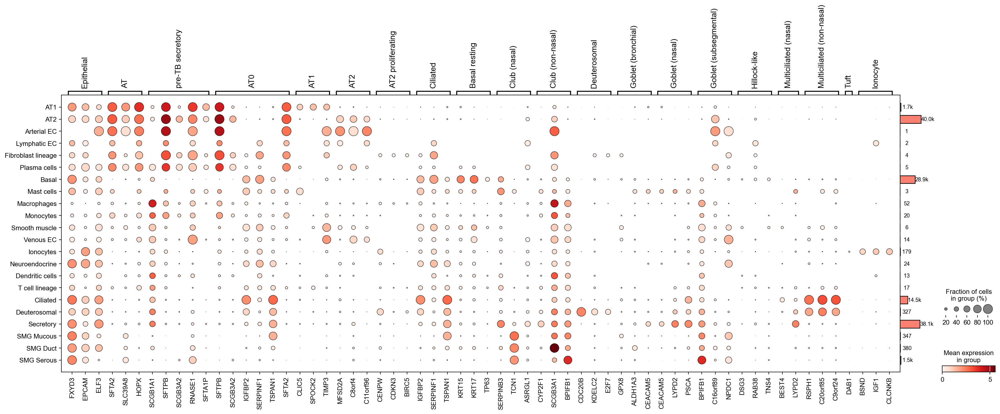

In [73]:
dp = sc.pl.dotplot(
    adata,
    var_names=markers['HLCA_epithelial'],
    groupby=f'{cluster_key}--{integration1}',
    dendrogram=True,
    return_fig=True,
)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

categories: AT1, AT2, Arterial EC, etc.
var_group_labels: Epithelial, AT, pre-TB secretory, etc.


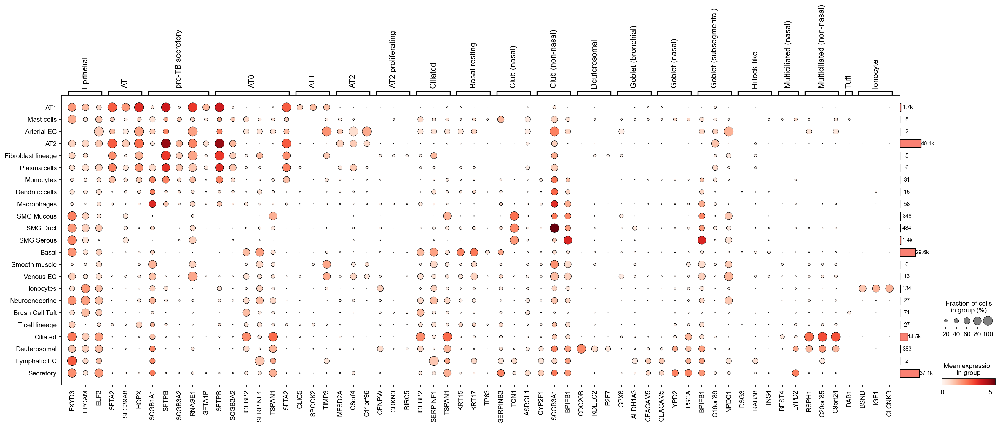

In [74]:
dp = sc.pl.dotplot(
    adata,
    var_names=markers['HLCA_epithelial'],
    groupby=f'{cluster_key}--{integration2}',
    dendrogram=True,
    return_fig=True,
)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

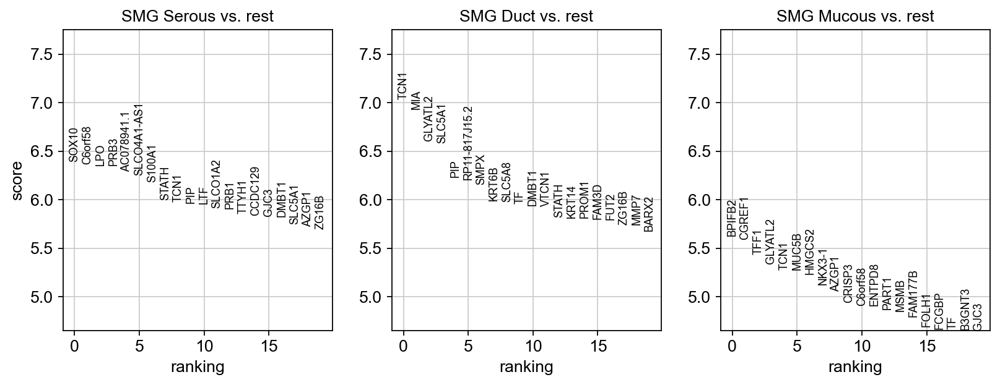

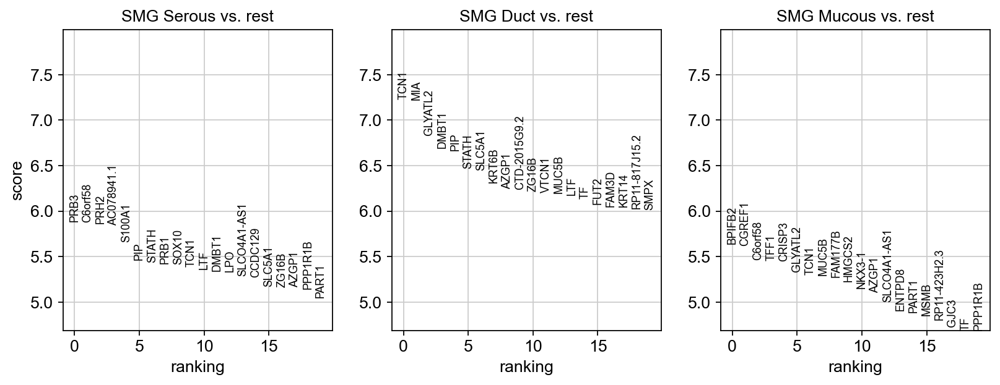

In [86]:
sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group={cluster_key}--{integration1}',
    groups=['SMG Serous', 'SMG Duct', 'SMG Mucous']
)
sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group={cluster_key}--{integration2}',
    groups=['SMG Serous', 'SMG Duct', 'SMG Mucous']
)

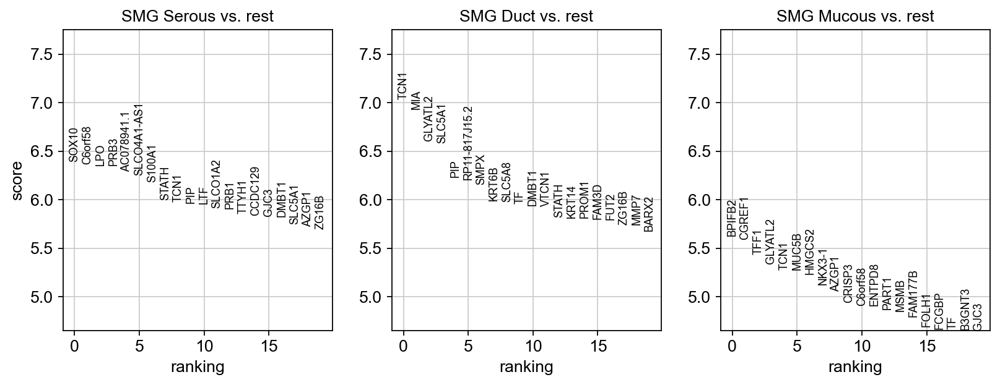

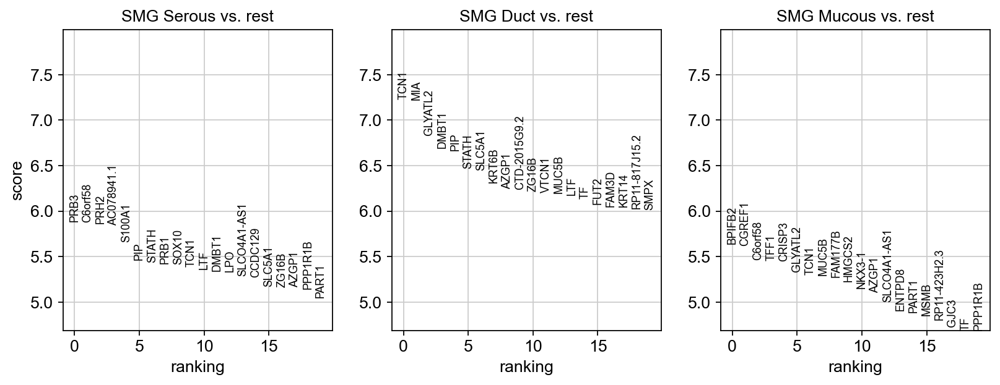

In [87]:
sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group={cluster_key}--{integration1}',
    groups=['SMG Serous', 'SMG Duct', 'SMG Mucous']
)
sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group={cluster_key}--{integration2}',
    groups=['SMG Serous', 'SMG Duct', 'SMG Mucous']
)

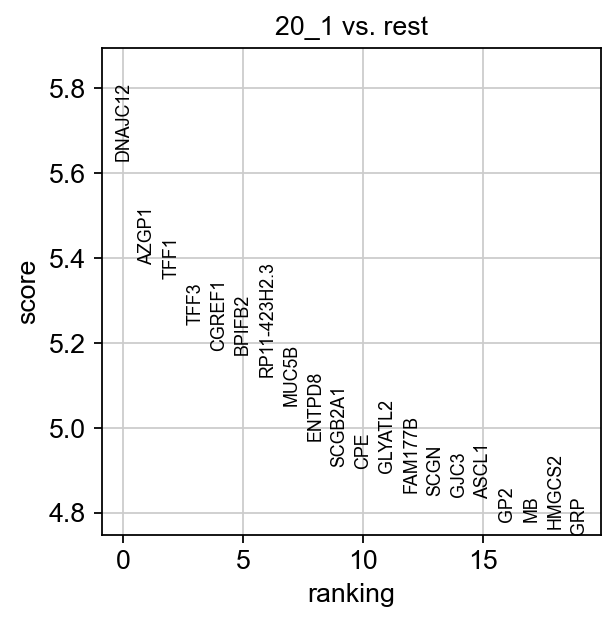

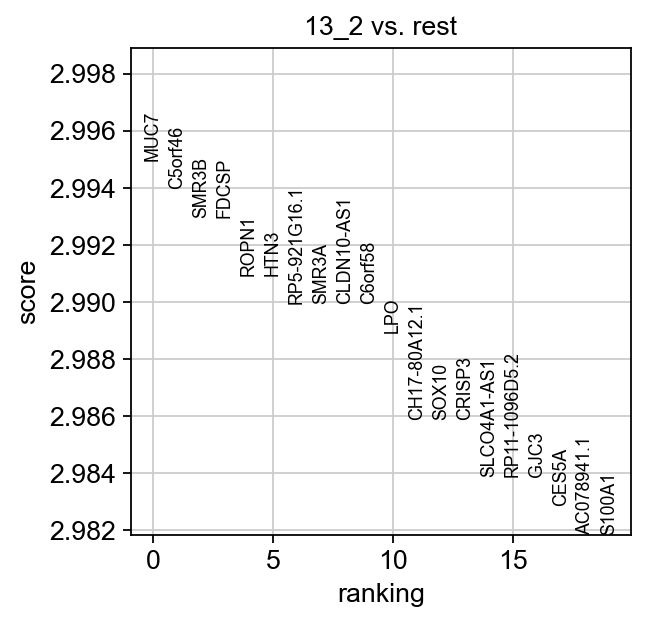

In [88]:
sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group=leiden_0.5_2--{integration1}',
    groups=['20_1']
)
sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group=leiden_0.5_2--{integration2}',
    groups=['13_2'],
)

# Graph dissimilarity

In [5]:
integration_alias = {
    'unintegrated': '530a81710b',
    'harmony': '2e34347366',
    'scvi': '13f239d804',
    'scanvi': '530a81710b',
}

In [6]:
method = 'scvi'

int1 = 'all'
int2 = 'qc'

integration1 = f'all--integration={integration_alias[method]}'
integration2 = f'qc--integration={integration_alias[method]}'

In [7]:
comparisons = [
    f'{int1}-vs-{int2}',
    f'{int2}-vs-{int1}'
]
metrics = [
    # 'avg_distance_1',
    # 'avg_distance_2',
    # 'avg_difference',
    'avg_distance_diff',
    # 'spearman_correlation'
]

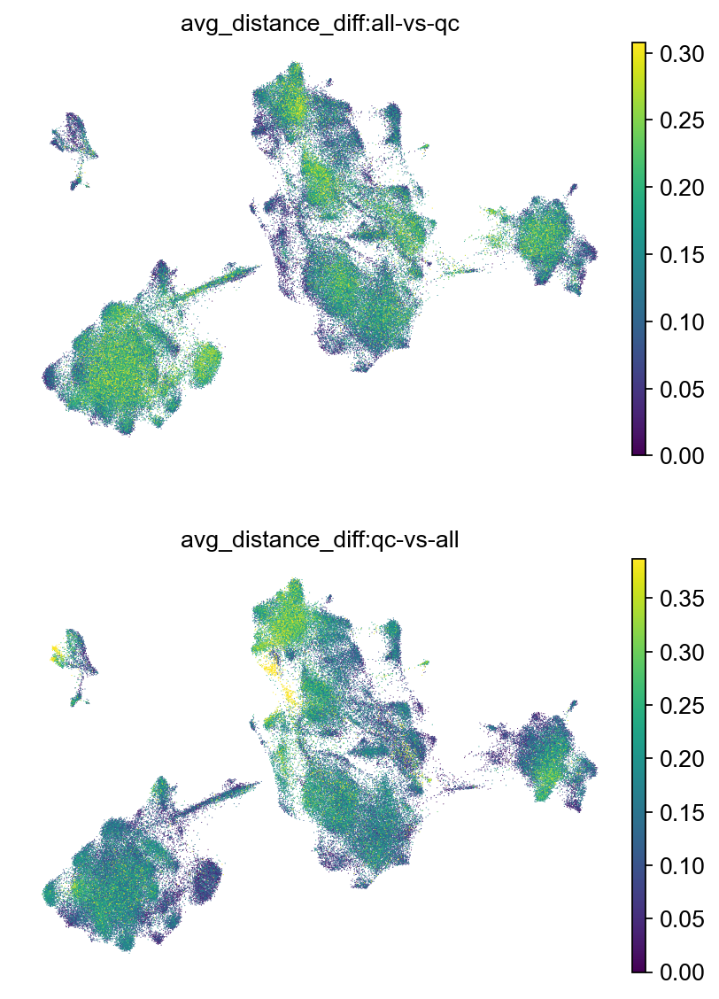

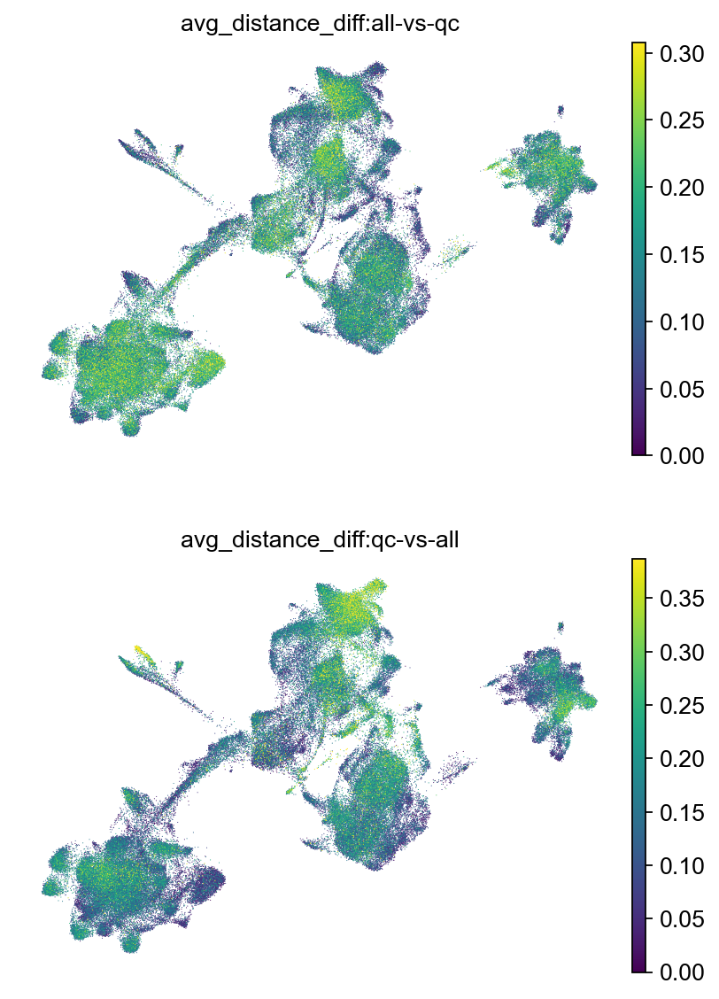

In [8]:
quantile = 0.99

for _metric in metrics:
    colors = [f'{_metric}:{comparison}' for comparison in comparisons]
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=colors,
        cmap='viridis',
        # size=5,
        ncols=len(metrics),
        wspace=0.5,
        # vmin=0,
        vmax=adata.obs[colors].quantile(quantile).tolist(),
        sort_order=True,
    )
 
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration2}',
        color=colors,
        cmap='viridis',
        # size=5,
        ncols=len(metrics),
        wspace=0.5,
        # vmin=0,
        vmax=adata.obs[colors].quantile(quantile).tolist(),
        sort_order=True,
    )

## UMAPs

In [76]:
colors = [
    'manual_ann',
    f'leiden_0.5_1--{integration1}',
    f'leiden_0.5_1--{integration2}',
    # f'leiden_0.5_2--{integration1}',
    # f'leiden_0.5_2--{integration2}',
    'study',
]

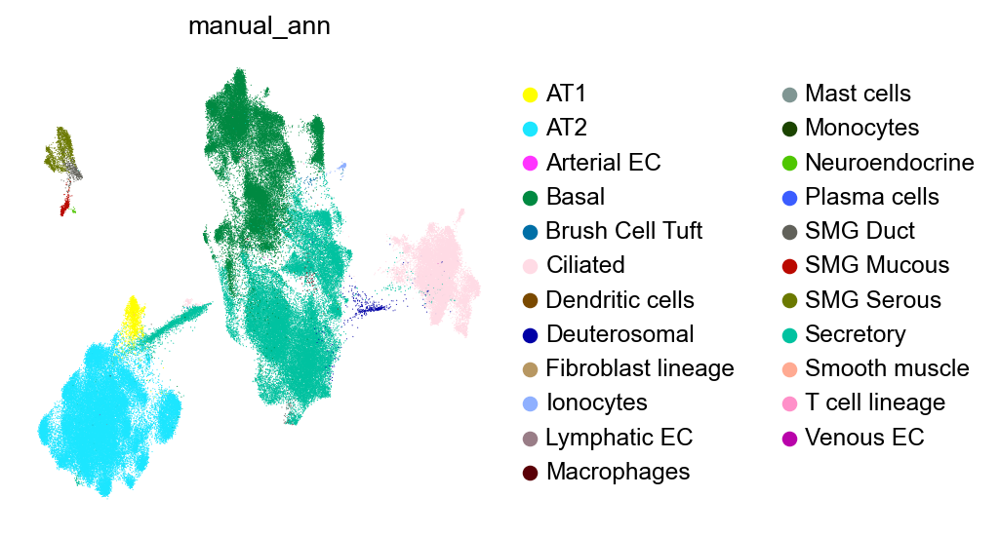

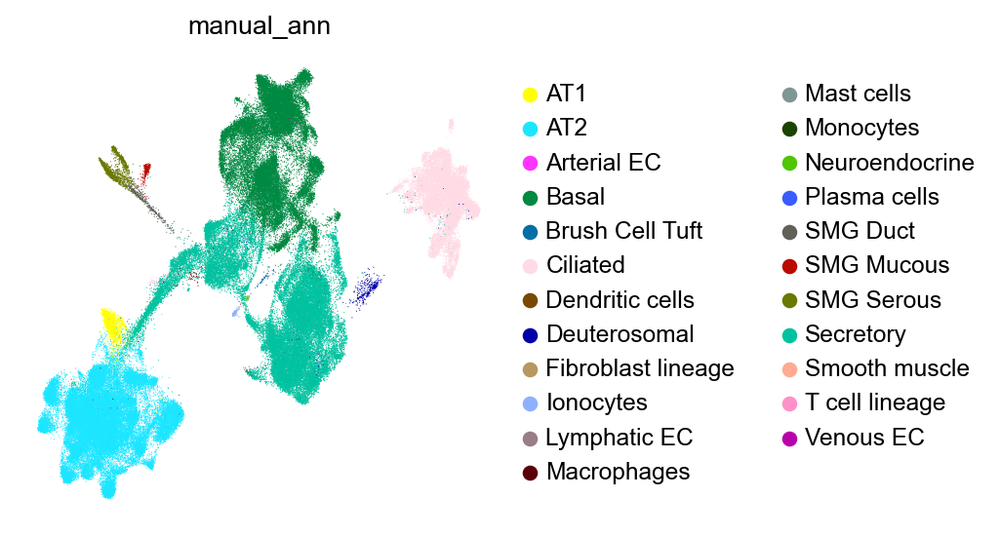

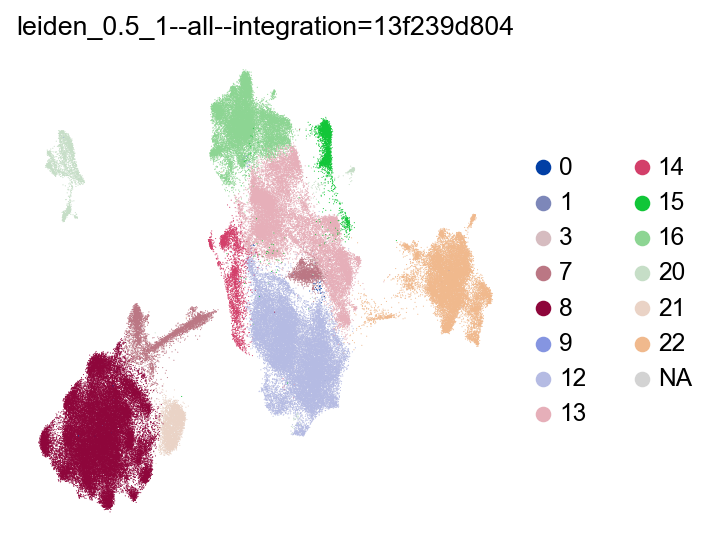

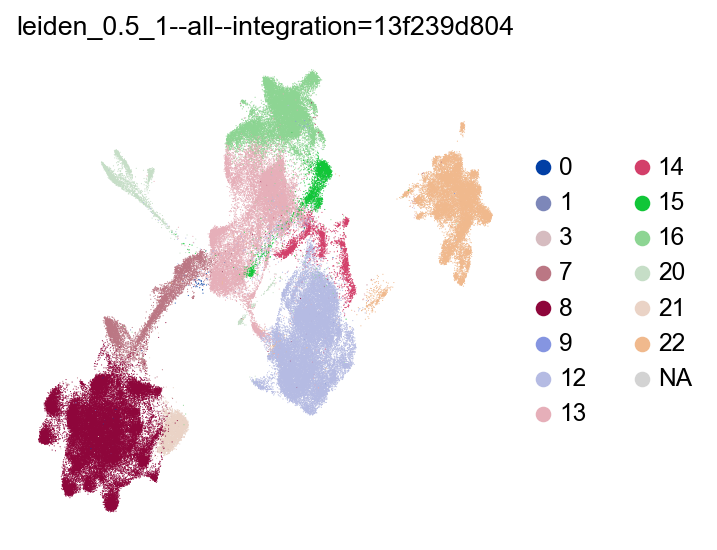

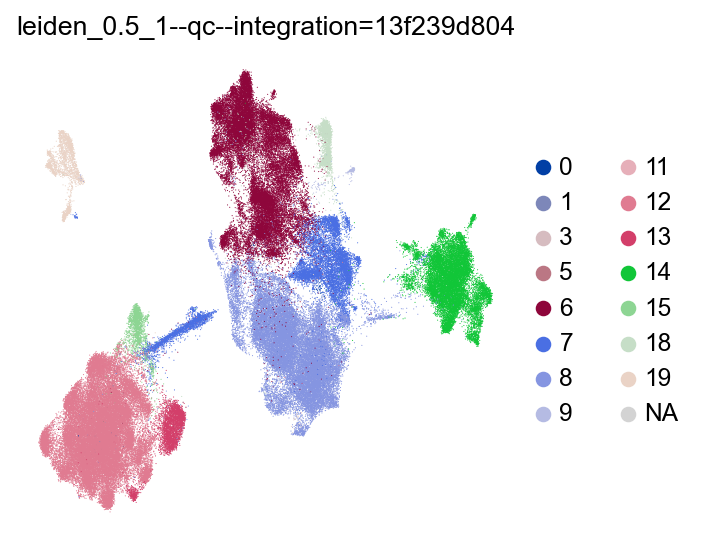

...

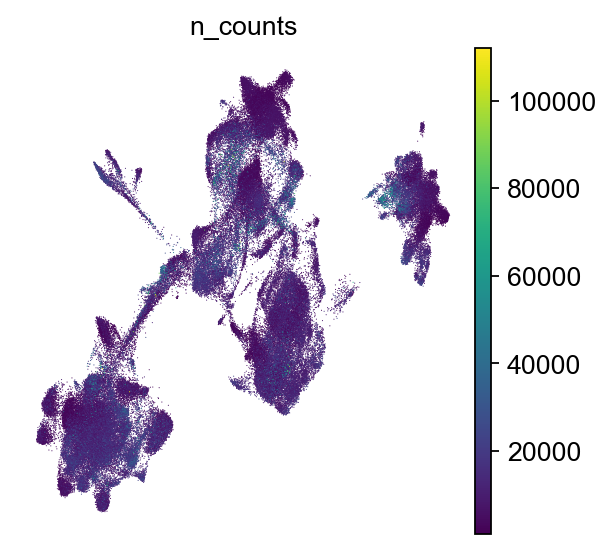

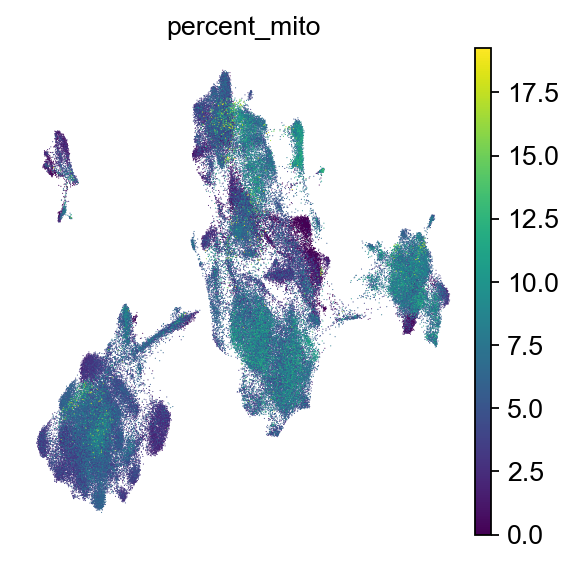

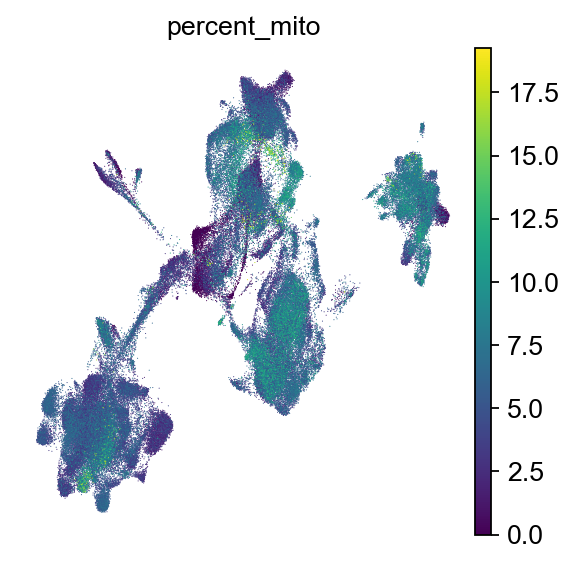

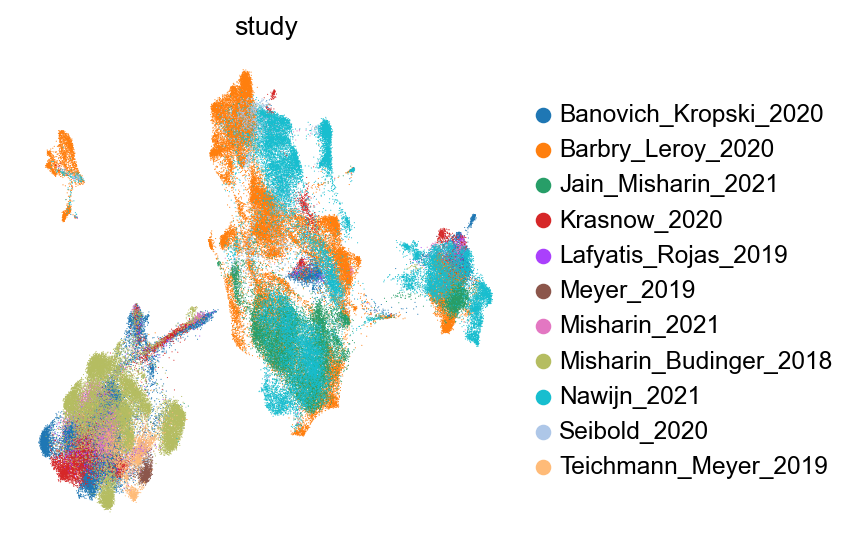

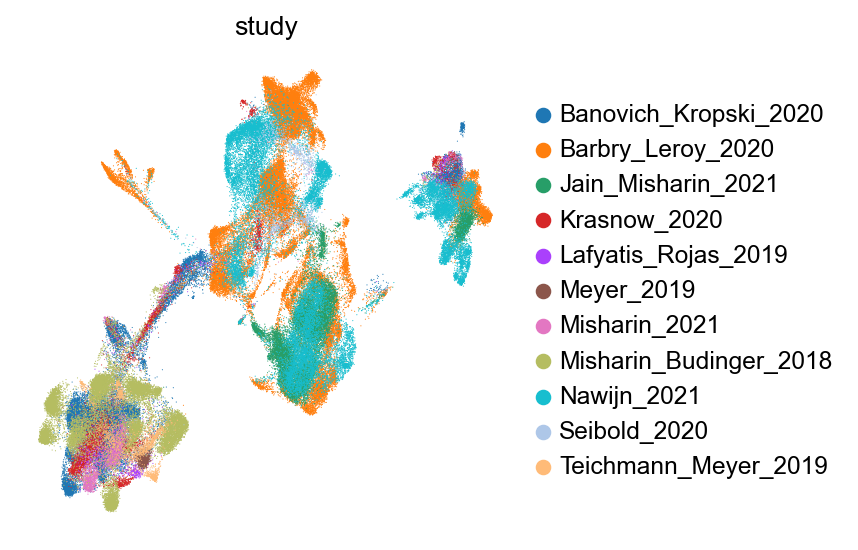

In [10]:
for col in colors:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=col,
        ncols=1,
    )

    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration2}',
        color=col,
        ncols=1,
    )

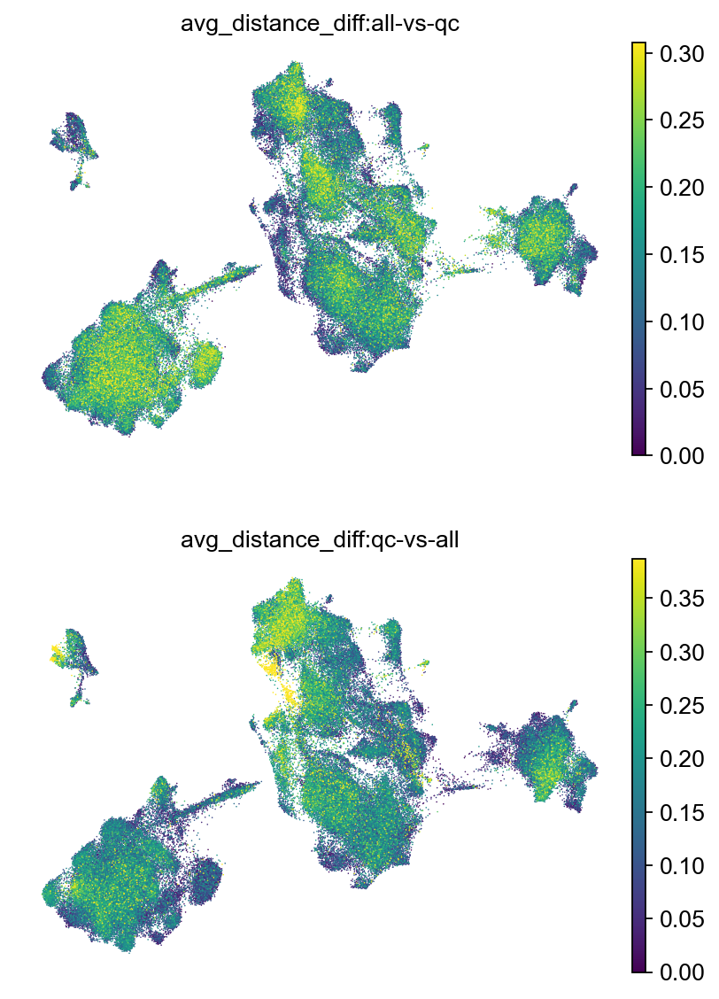

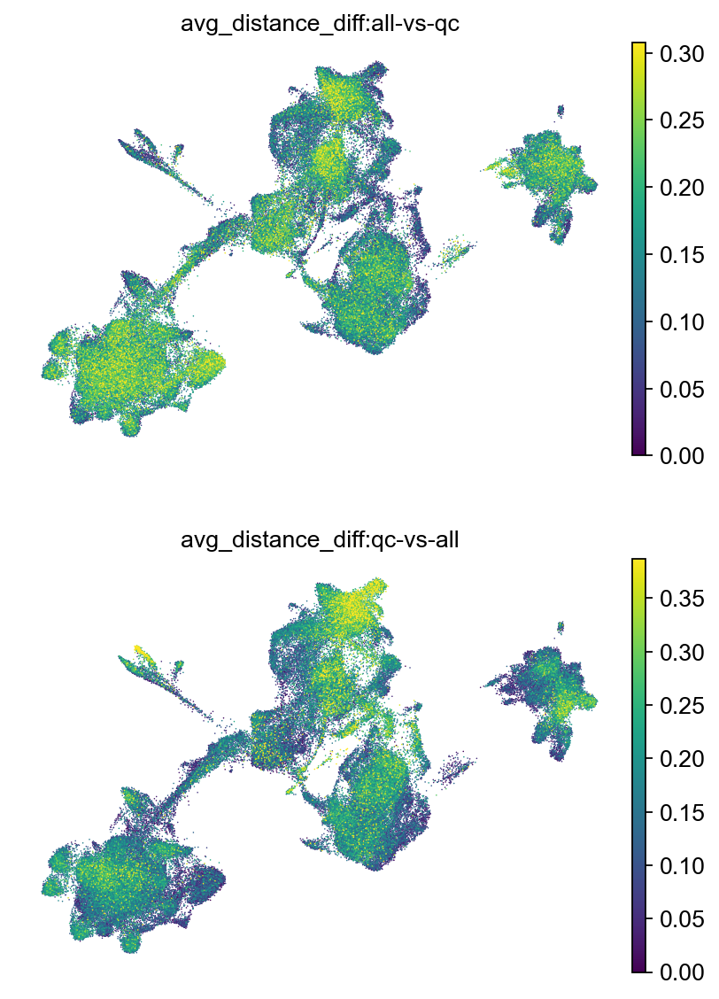

In [11]:
for _metric in metrics:
    gd_colors = [f'{_metric}:{comparison}' for comparison in comparisons]
    color_bool = [f'{col}_bool' for col in gd_colors]
    for col in gd_colors:
        adata.obs[f'{col}_bool'] = adata.obs[f'{col}'] > 0.1
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=gd_colors,
        cmap='viridis',
        size=2,
        ncols=len(metrics),
        wspace=0.5,
        # vmin=0,
        vmax=adata.obs[gd_colors].quantile(quantile).tolist(),
        sort_order=True,
    )
 
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration2}',
        color=gd_colors,
        cmap='viridis',
        size=2,
        ncols=len(metrics),
        wspace=0.5,
        # vmin=0,
        vmax=adata.obs[gd_colors].quantile(quantile).tolist(),
        sort_order=True,
    )

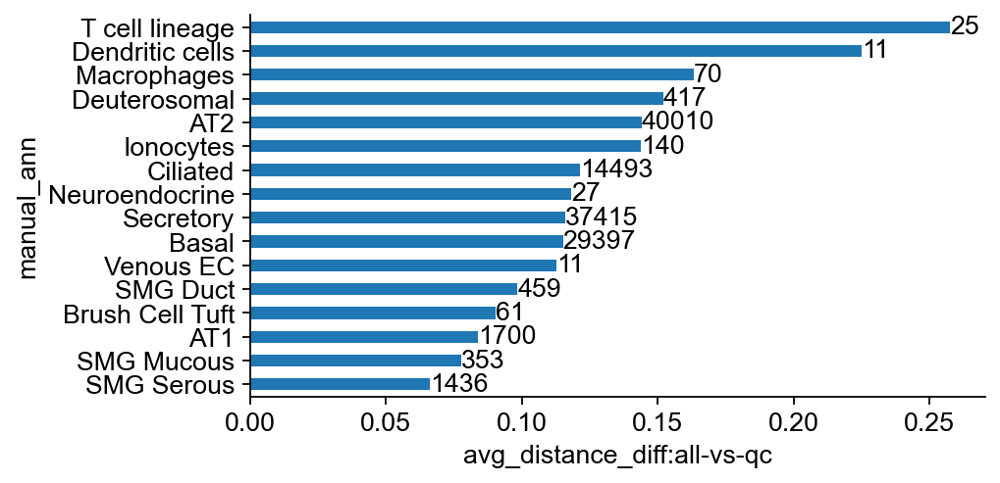

manual_ann
SMG Serous         0.066177
SMG Mucous         0.077800
AT1                0.083877
Brush Cell Tuft    0.090248
SMG Duct           0.098410
Venous EC          0.112664
Basal              0.115153
Secretory          0.116062
Neuroendocrine     0.118273
Ciliated           0.121419
Ionocytes          0.143632
AT2                0.144123
Deuterosomal       0.152068
Macrophages        0.163211
Dendritic cells    0.225188
T cell lineage     0.257518
Name: avg_distance_diff:all-vs-qc, dtype: float64

In [12]:
plot_diff_per_clusters(
    adata,
    'manual_ann',
    f'avg_distance_diff:{int1}-vs-{int2}',
)

In [40]:
cluster_key = 'leiden_0.5_1'

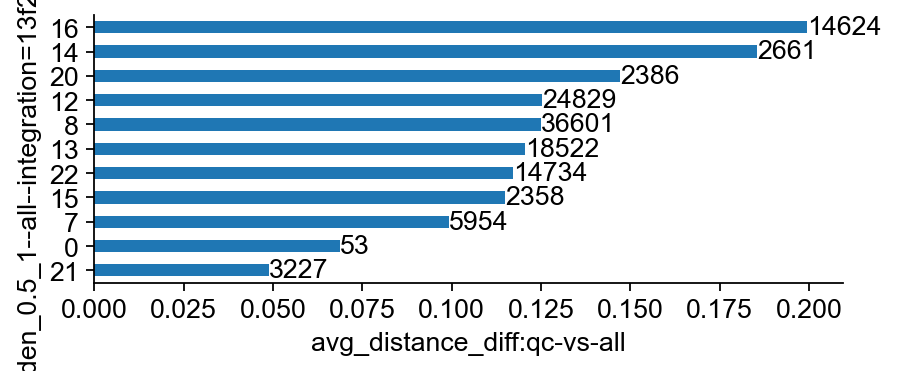

In [14]:
int1_clusters = plot_diff_per_clusters(
    adata,
    f'{cluster_key}--{integration1}',
    f'avg_distance_diff:{int2}-vs-{int1}',
    agg='median',
    cluster_thresh=50,
)

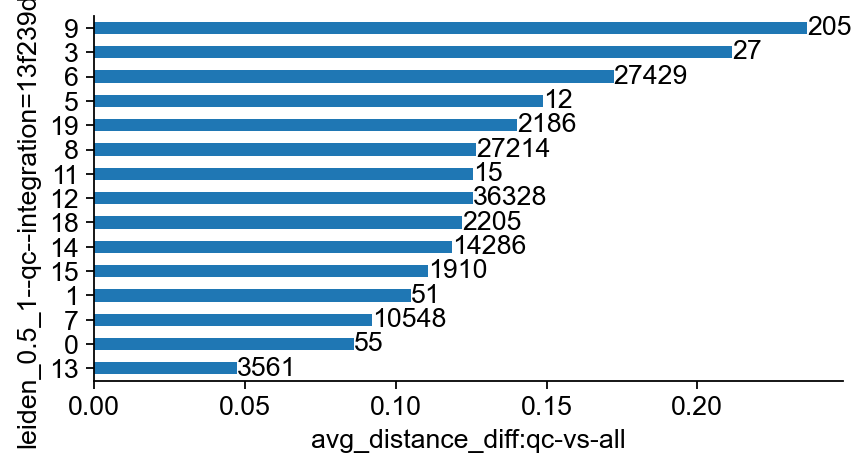

In [15]:
int2_clusters = plot_diff_per_clusters(
    adata,
    f'{cluster_key}--{integration2}',
    f'avg_distance_diff:{int2}-vs-{int1}',
    agg='median',
)

In [16]:
n_top = 5

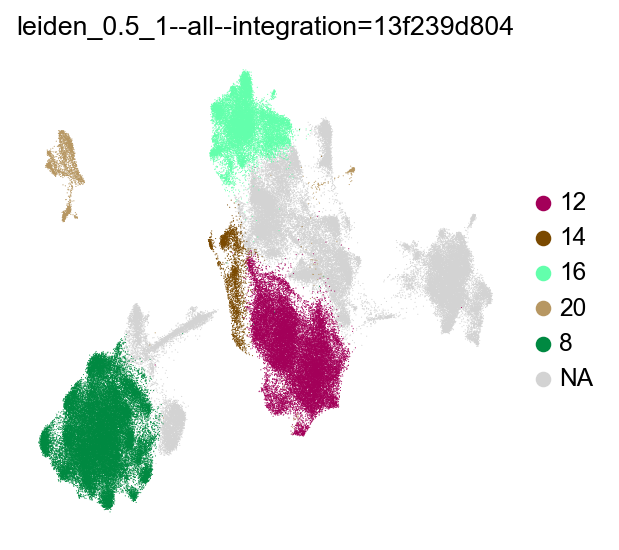

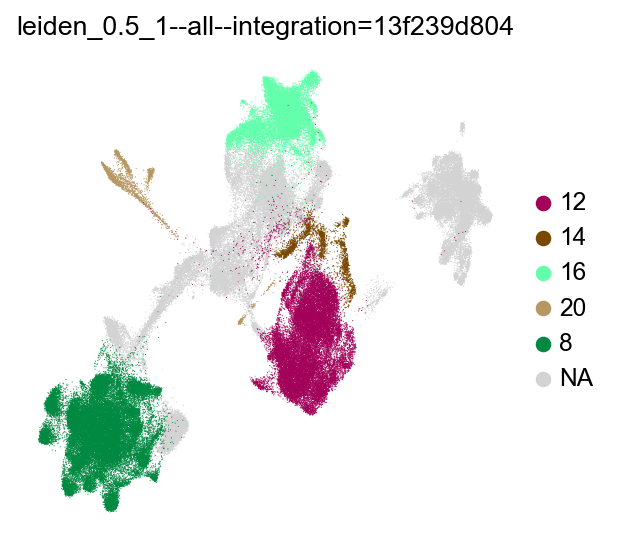

In [17]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=f'{cluster_key}--{integration1}',
    groups=int1_clusters[-n_top:].index.tolist(),
    ncols=1,
    palette=sc.pl.palettes.default_102,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'{cluster_key}--{integration1}',
    groups=int1_clusters[-n_top:].index.tolist(),
    ncols=1,
    palette=sc.pl.palettes.default_102,
)

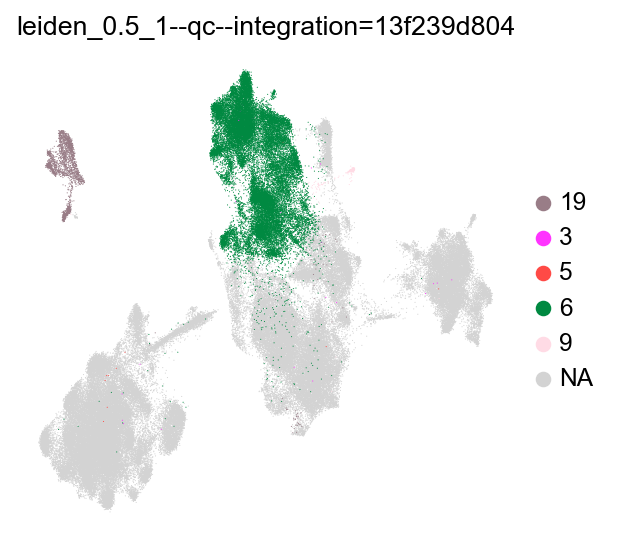

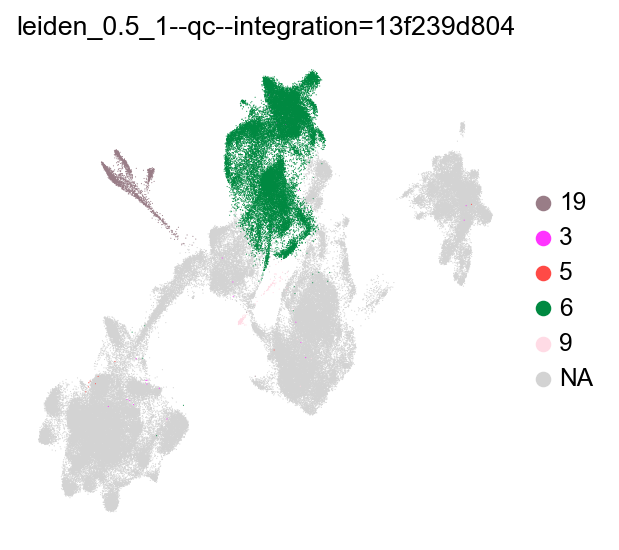

In [18]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=f'{cluster_key}--{integration2}',
    groups=int2_clusters[-n_top:].index.tolist(),
    ncols=1,
    palette=sc.pl.palettes.default_102,
)
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'{cluster_key}--{integration2}',
    groups=int2_clusters[-n_top:].index.tolist(),
    ncols=1,
    palette=sc.pl.palettes.default_102,
)

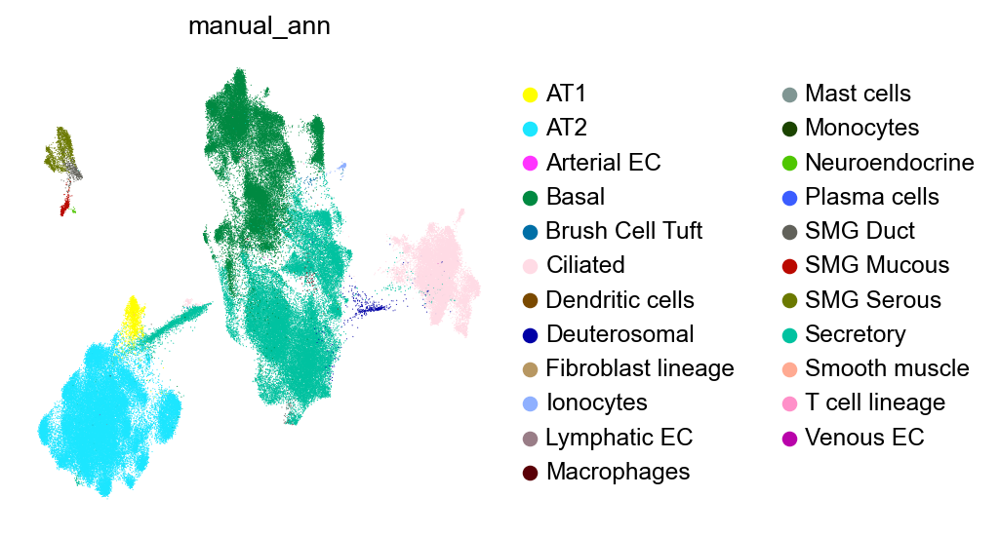

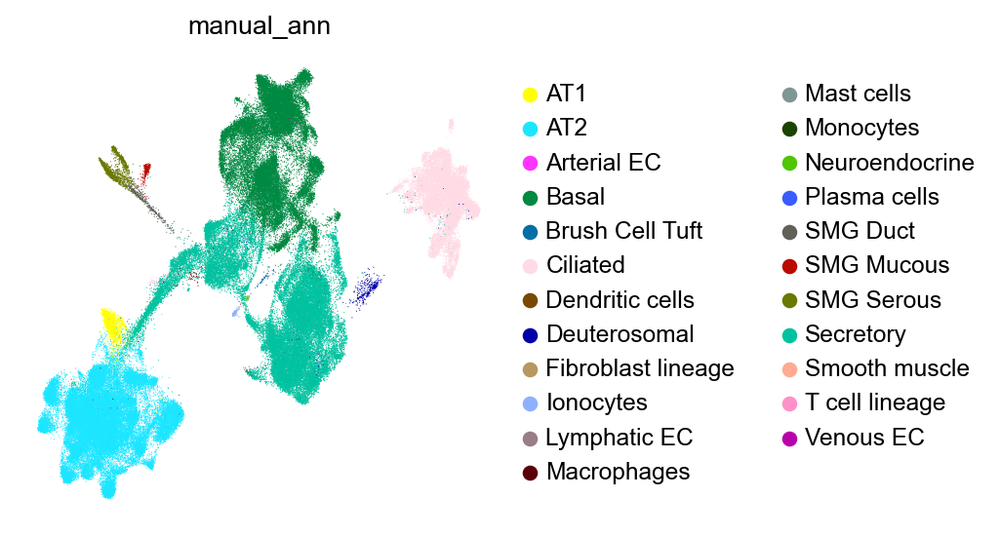

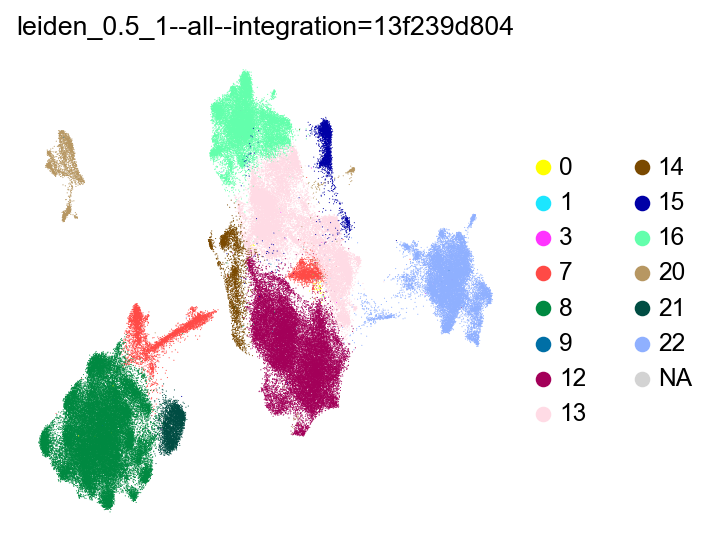

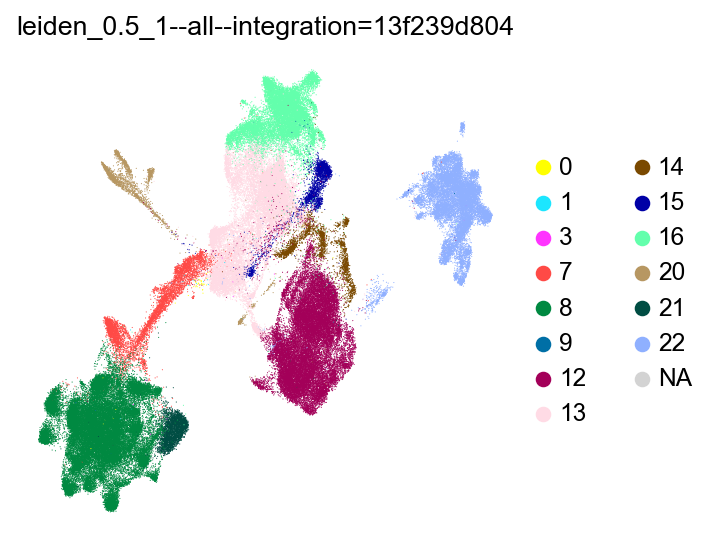

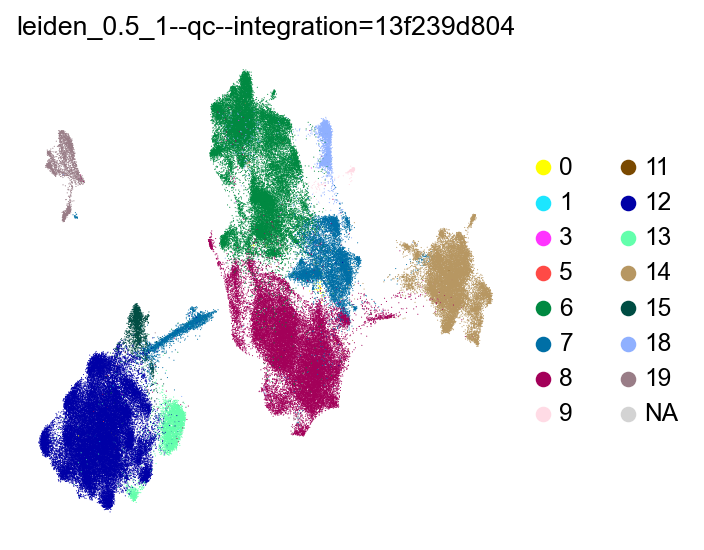

...

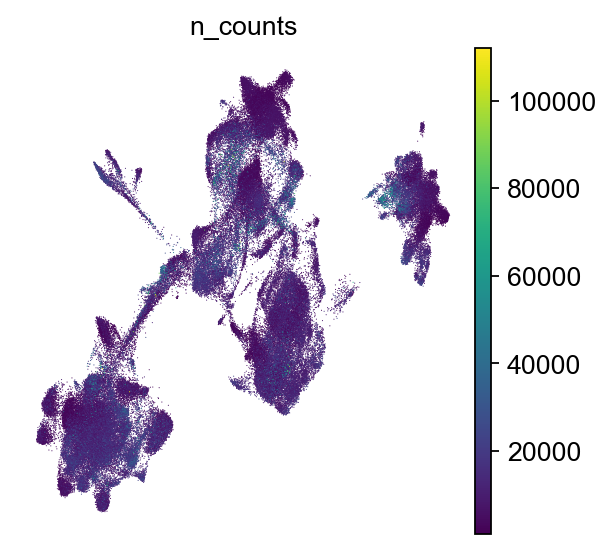

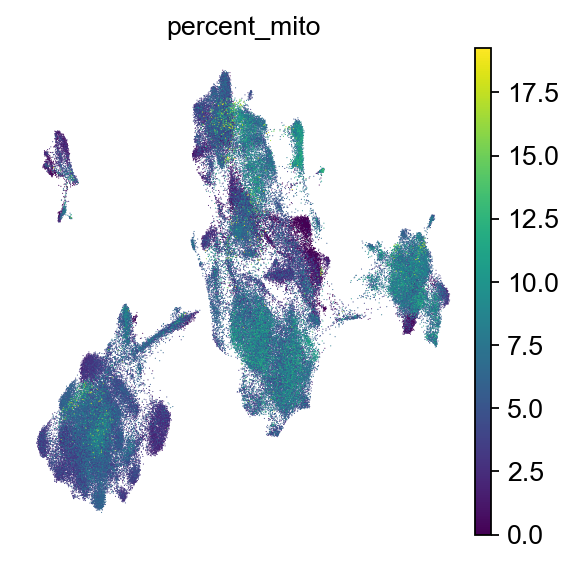

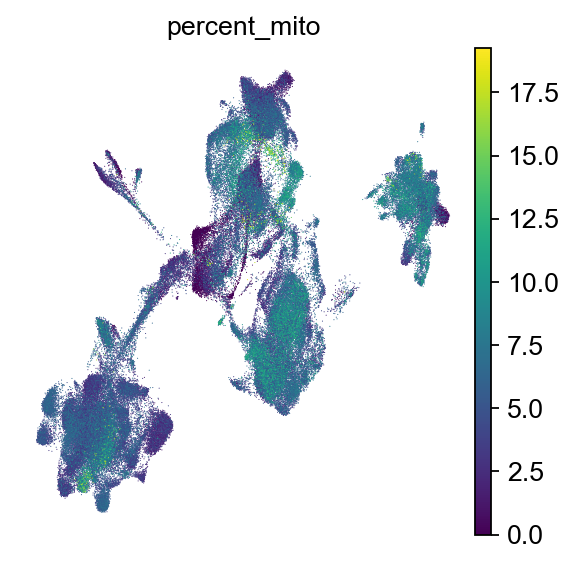

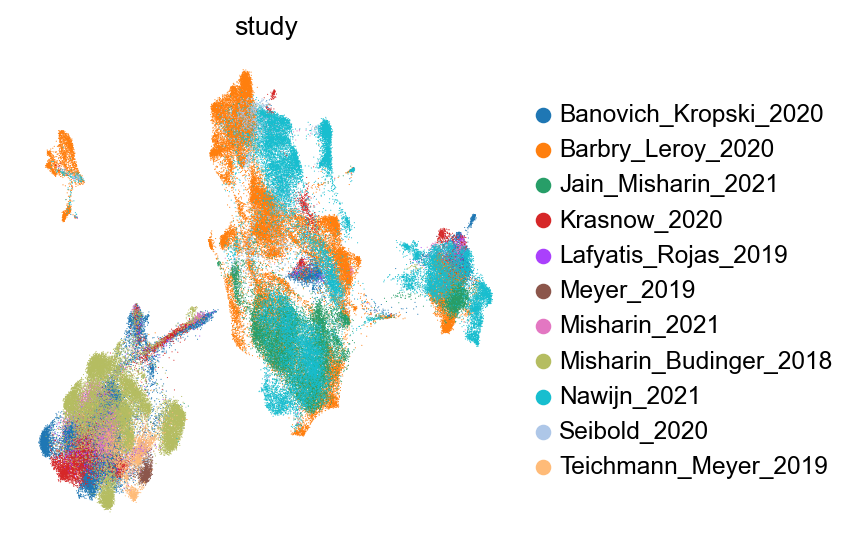

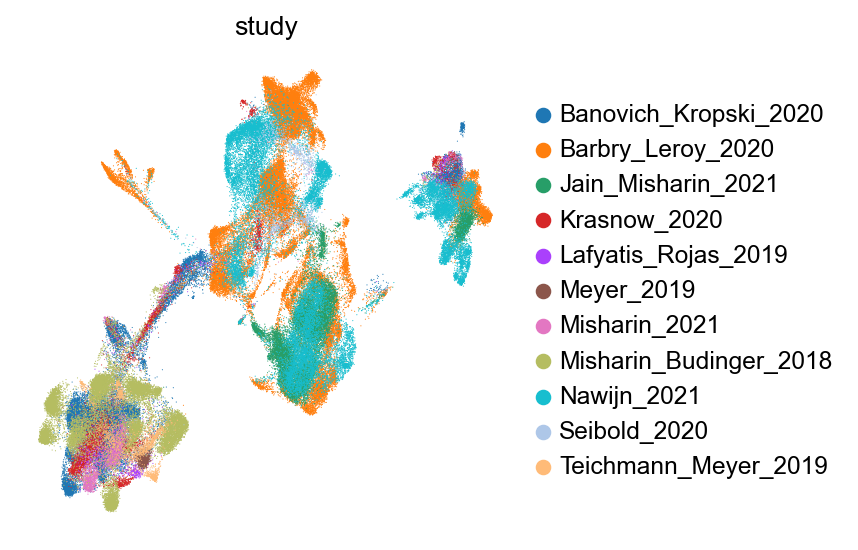

In [19]:
for col in colors:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=col,
        ncols=1,
    )
    
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration2}',
        color=col,
        ncols=1,
    )

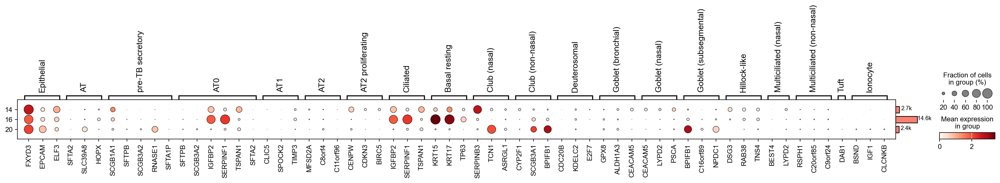

In [75]:
dp = sc.pl.dotplot(
    adata[adata.obs[f'leiden_0.5_1--{integration1}'].isin(int1_clusters[-3:].index.tolist())],
    var_names=markers['HLCA_epithelial'],
    groupby=f'leiden_0.5_1--{integration1}',
    dendrogram=False,
    return_fig=True,
    # swap_axes=True,
)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

In [90]:
sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group=leiden_0.5_3--{integration1}',
    groups=[x for x in adata.obs[f'leiden_0.5_3--{integration1}'].unique() if str(x).startswith('20_1')]
)

sc.pl.rank_genes_groups(
    adata,
    key=f'marker_genes_group=leiden_0.5_3--{integration2}',
    groups=[x for x in adata.obs[f'leiden_0.5_3--{integration2}'].unique() if str(x).startswith('13_2')],
)

AttributeError: 'float' object has no attribute 'startswith'

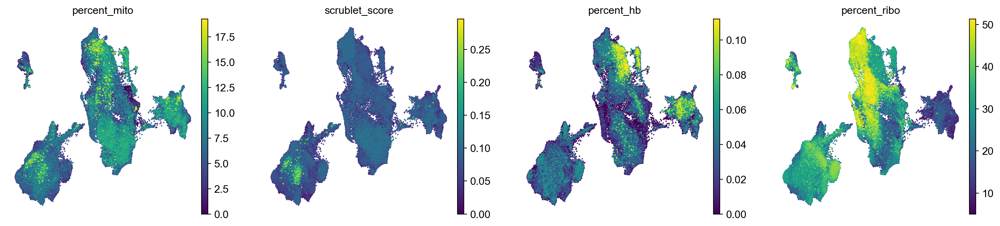

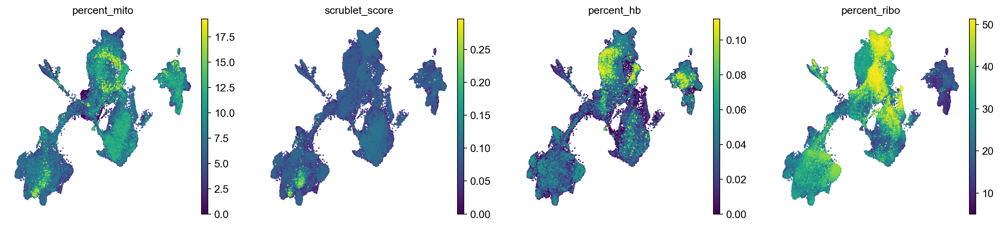

In [26]:
qc_colors = ['percent_mito', 'scrublet_score', 'percent_hb', 'percent_ribo']

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=qc_colors,
    size=10,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=qc_colors,
    size=10,
)

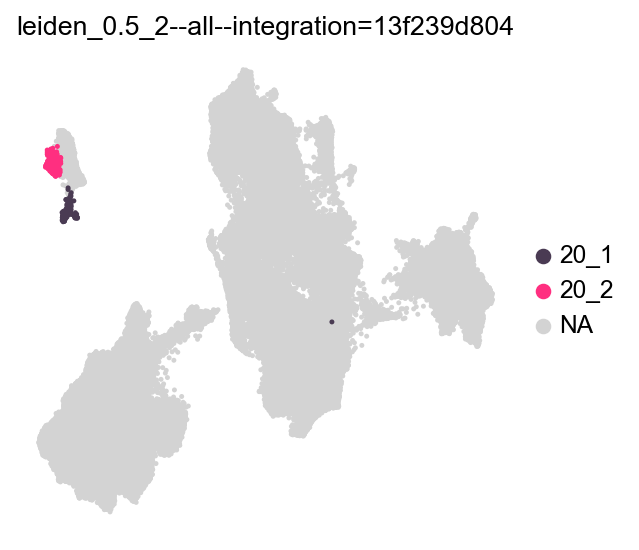

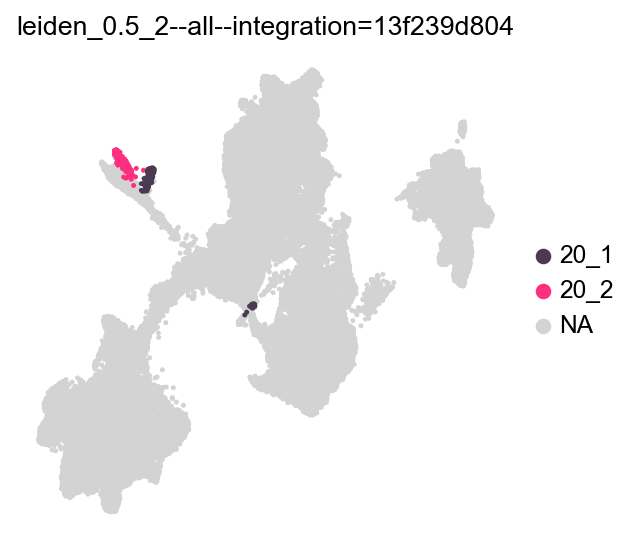

In [20]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=f'leiden_0.5_2--{integration1}',
    groups=['20_1', '20_2'],
    size=20,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'leiden_0.5_2--{integration1}',
    groups=['20_1', '20_2'],
    size=20,
)

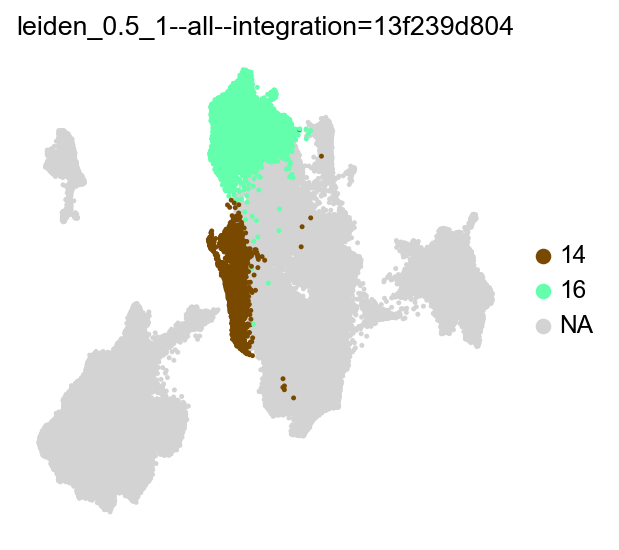

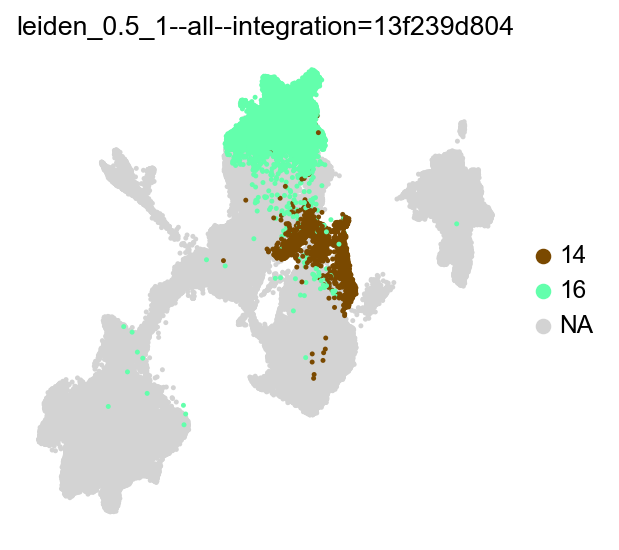

In [21]:
groups = [x for x in adata.obs[f'leiden_0.5_3--{integration1}'].unique() if str(x).startswith('20_1')]
groups = int1_clusters[-2:].index.tolist()

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=f'{cluster_key}--{integration1}',
    groups=groups,
    size=20,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'{cluster_key}--{integration1}',
    groups=groups,
    size=20,
)

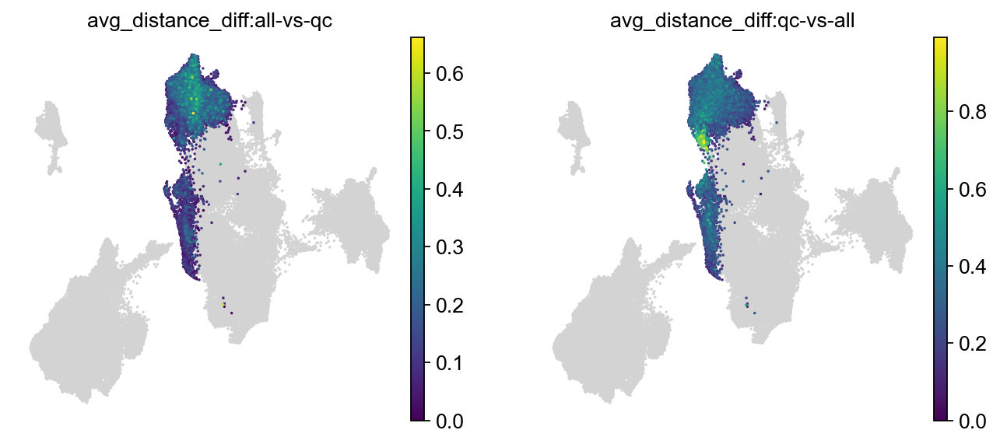

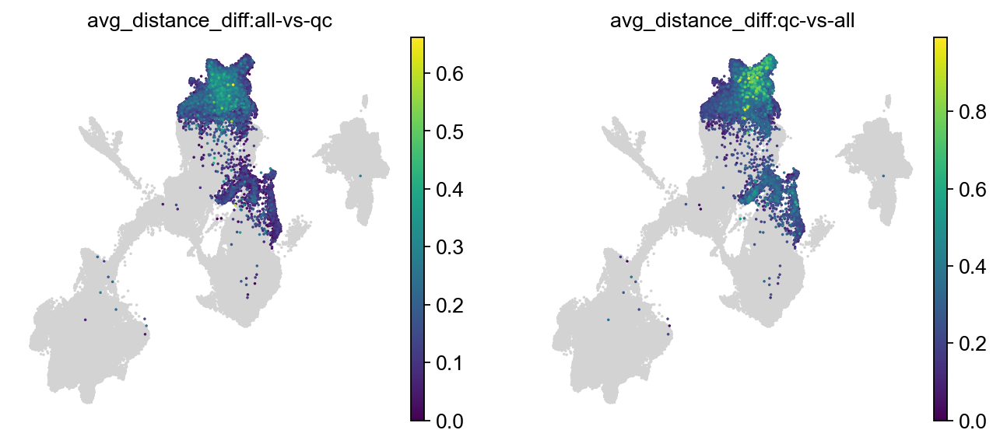

In [22]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=gd_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration1}'].isin(groups),
    size=10,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=gd_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration1}'].isin(groups),
    size=10,
)

In [23]:
adata[adata.obs[f'{cluster_key}--{integration1}'].isin(groups)].obs['manual_ann'].value_counts()

manual_ann
Basal              16318
Secretory            945
T cell lineage         6
AT2                    5
Ciliated               5
Brush Cell Tuft        4
Dendritic cells        1
Mast cells             1
Name: count, dtype: int64

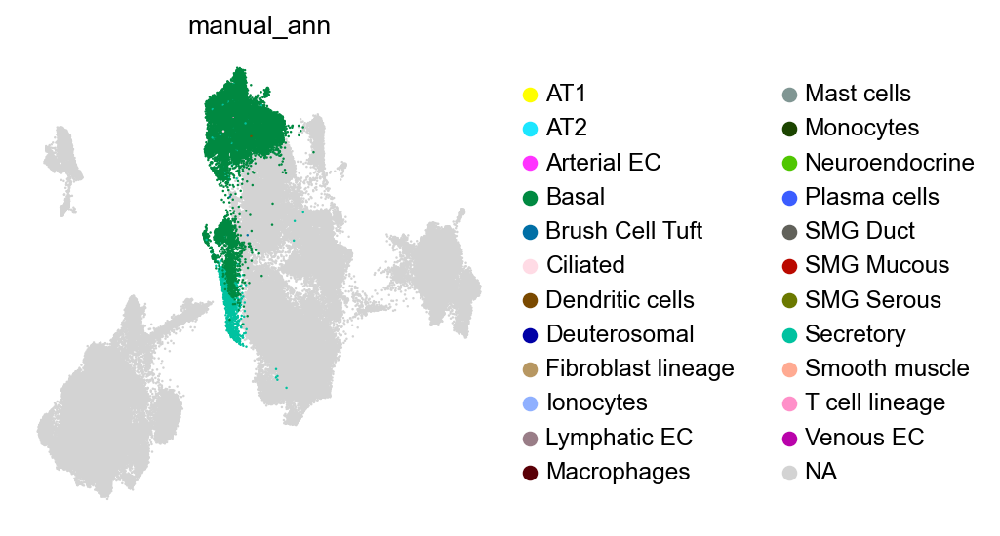

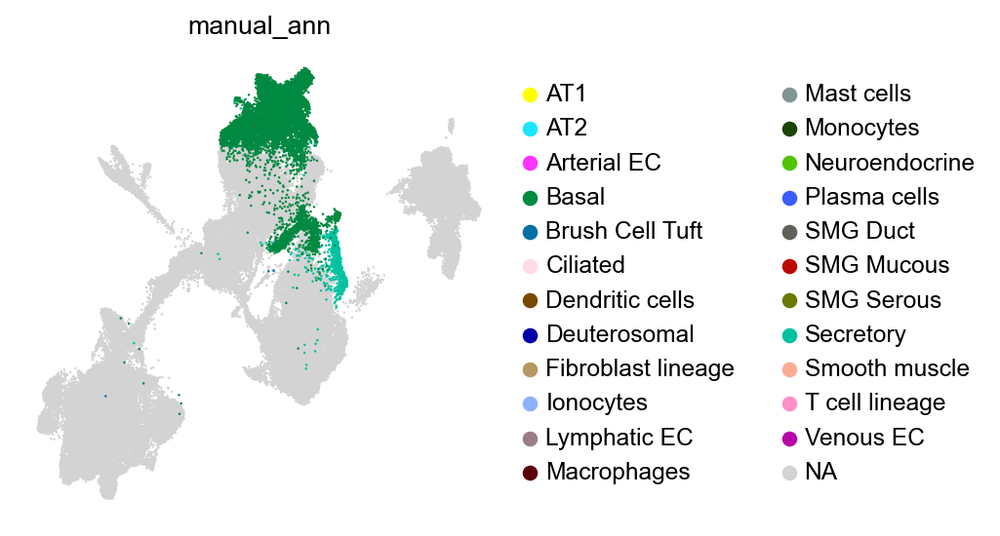

In [24]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color='manual_ann',
    mask_obs=adata.obs[f'{cluster_key}--{integration1}'].isin(groups),
    size=5,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color='manual_ann',
    mask_obs=adata.obs[f'{cluster_key}--{integration1}'].isin(groups),
    size=5,
)

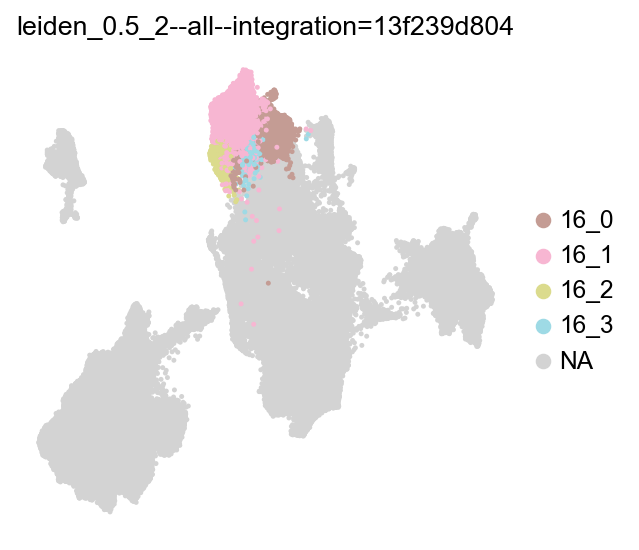

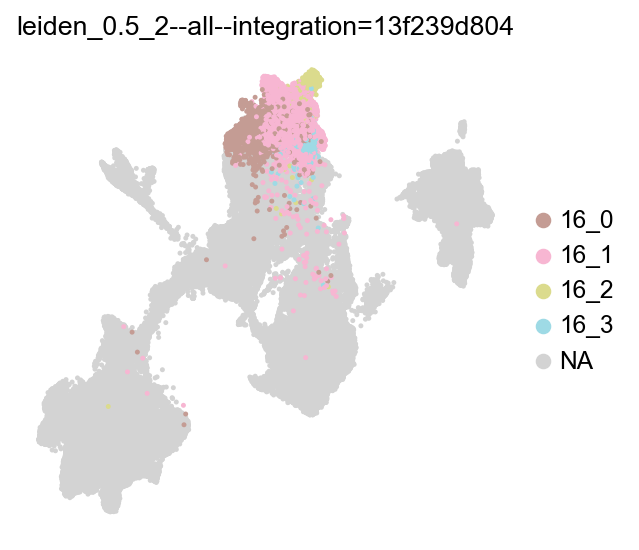

In [34]:
cluster_key = 'leiden_0.5_2'
groups = [x for x in adata.obs[f'{cluster_key}--{integration1}'] if str(x).startswith('16')]

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=f'{cluster_key}--{integration1}',
    groups=groups,
    size=20,
    palette=sc.pl.palettes.default_20,
    # palette=sc.pl.palettes.default_102,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'{cluster_key}--{integration1}',
    groups=groups,
    palette=sc.pl.palettes.default_20,
    # palette=sc.pl.palettes.default_102,
    size=20,
)

In [59]:
cluster_key = 'leiden_0.5_1'

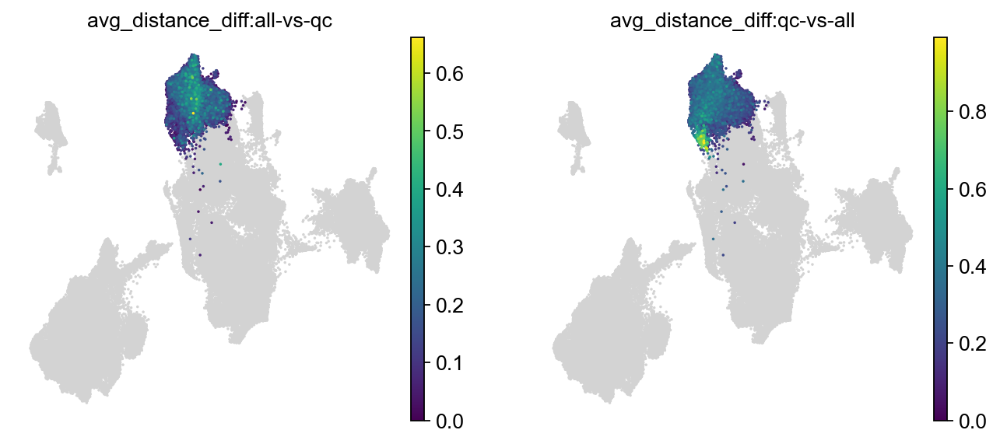

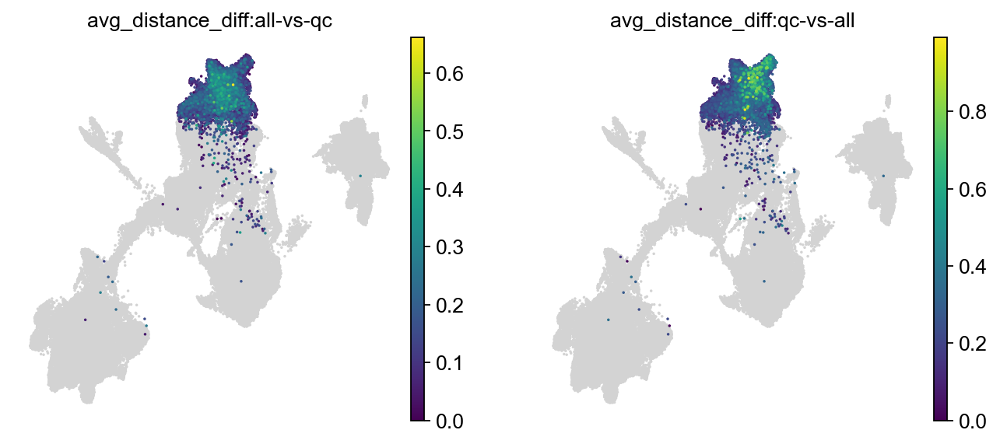

In [36]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=gd_colors,
    mask_obs=adata.obs[f'leiden_0.5_1--{integration1}'] == '16',
    size=10,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=gd_colors,
    mask_obs=adata.obs[f'leiden_0.5_1--{integration1}'] == '16',
    size=10,
)

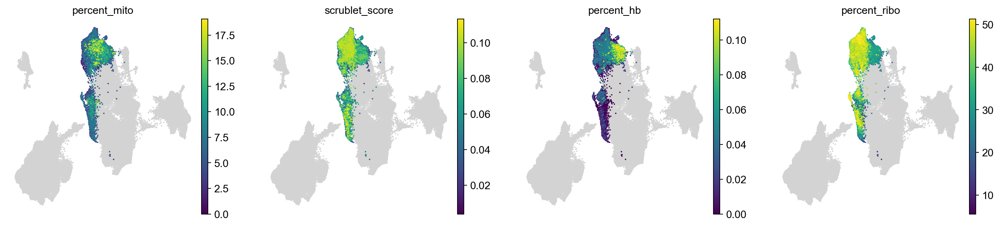

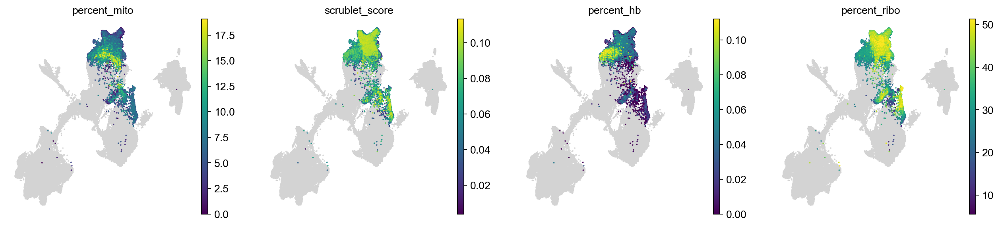

In [25]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=qc_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration1}'].isin(groups),
    size=10,
    ncols=len(qc_colors),
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=qc_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration1}'].isin(groups),
    size=10,
    ncols=len(qc_colors),
)

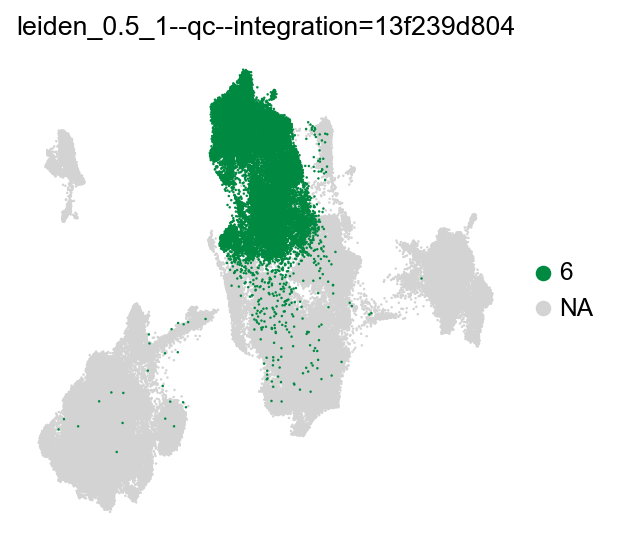

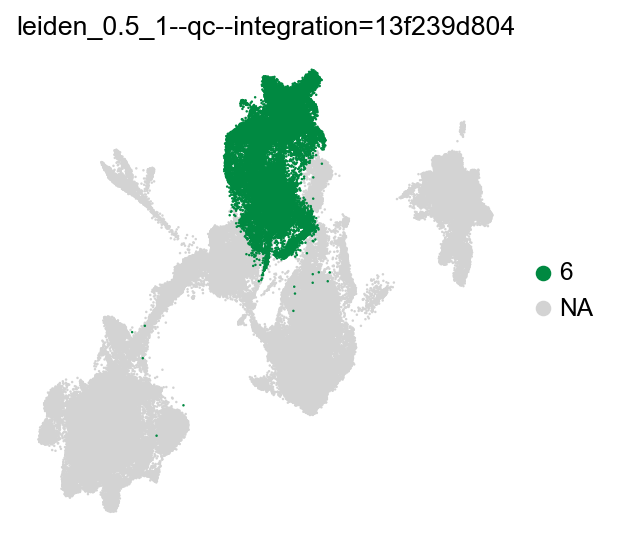

In [60]:
groups = int2_clusters[-3:].index.tolist()
groups = ['6']

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=f'{cluster_key}--{integration2}',
    groups=groups,
    size=5,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'{cluster_key}--{integration2}',
    groups=groups,
    size=5,
)

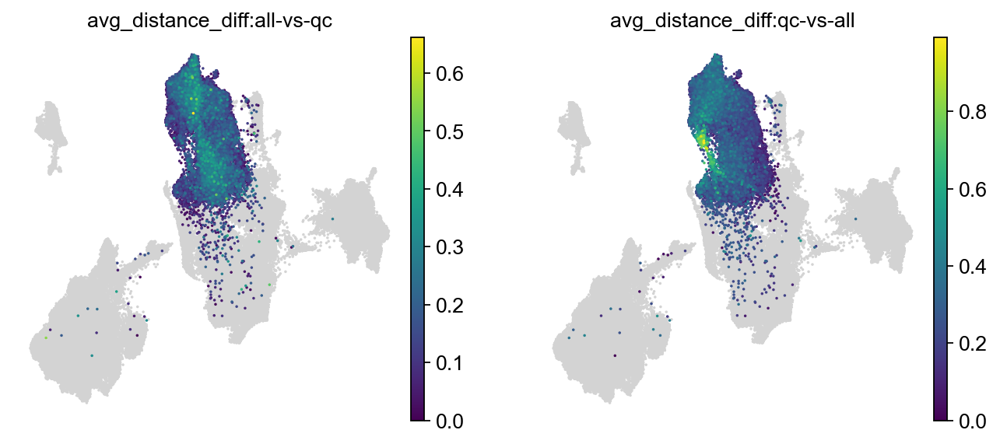

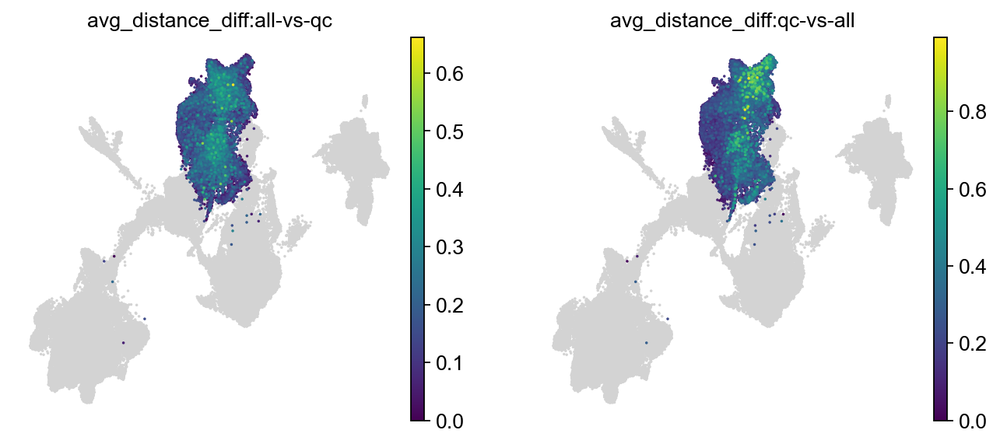

In [50]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=gd_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration2}'].isin(groups),
    size=10,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=gd_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration2}'].isin(groups),
    size=10,
)

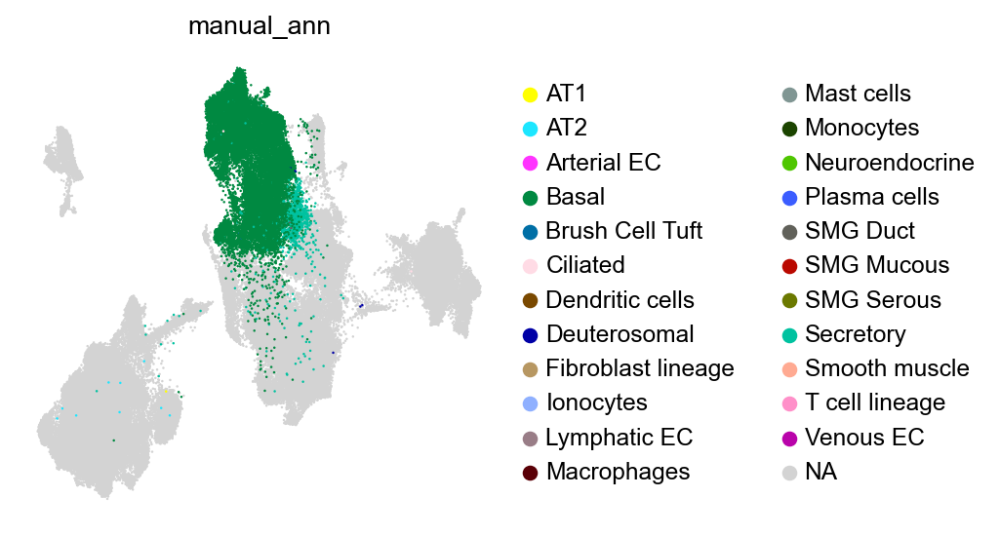

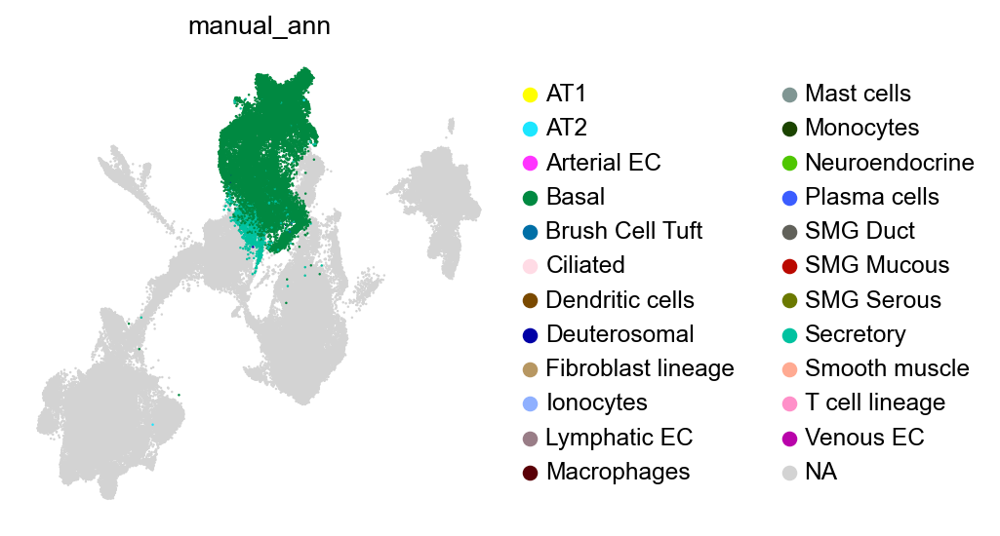

In [41]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color='manual_ann',
    mask_obs=adata.obs[f'{cluster_key}--{integration2}'] == '6',
    size=5,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color='manual_ann',
    mask_obs=adata.obs[f'{cluster_key}--{integration2}'] == '6',
    size=5,
)

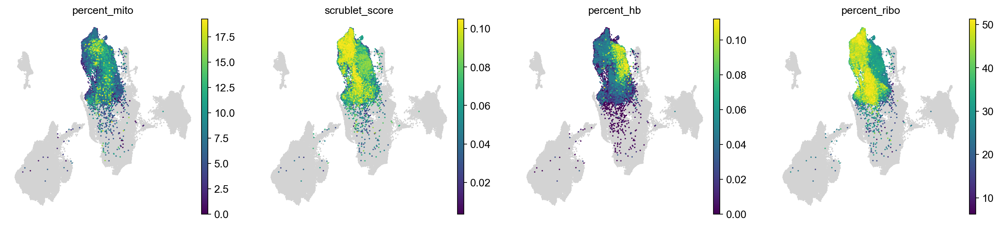

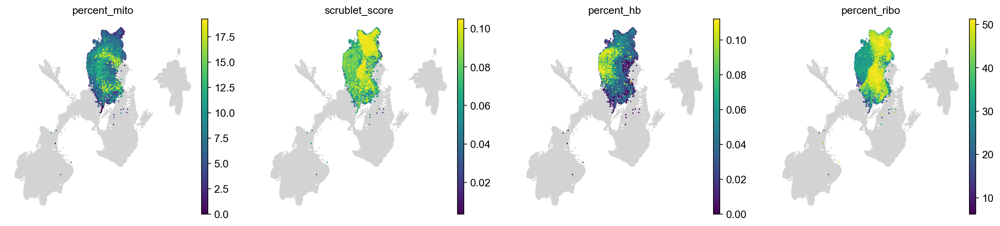

In [61]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=qc_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration2}'] == '6',
    size=10,
    ncols=len(qc_colors),
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=qc_colors,
    mask_obs=adata.obs[f'{cluster_key}--{integration2}'] == '6',
    size=10,
    ncols=len(qc_colors),
)

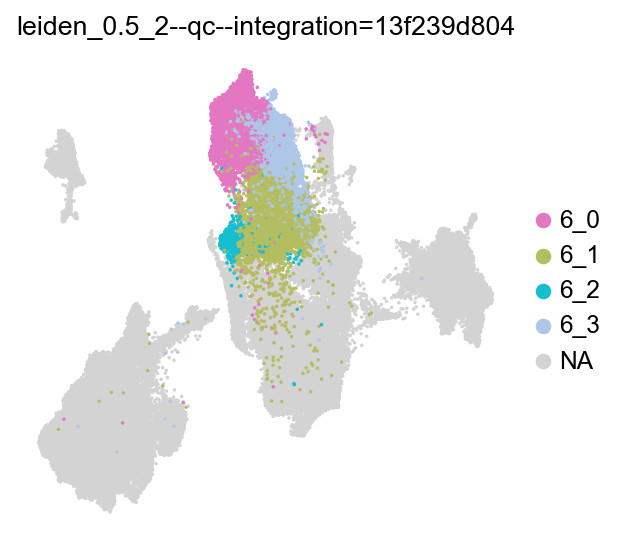

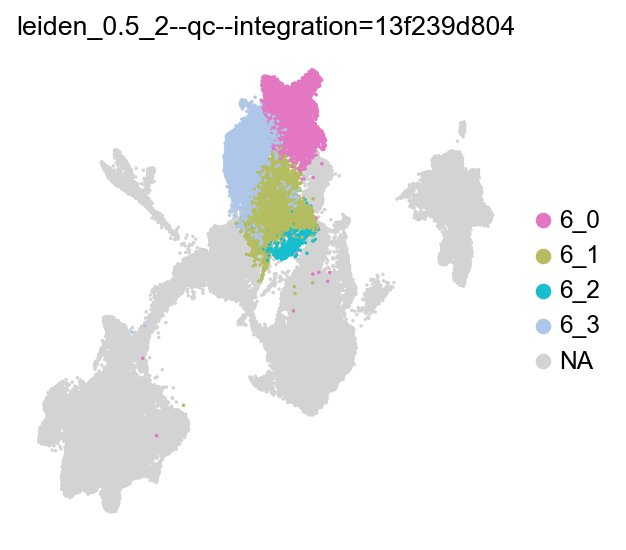

In [63]:
cluster_key = 'leiden_0.5_2'
groups = [x for x in adata.obs[f'{cluster_key}--{integration2}'] if str(x).startswith('6')]

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=f'{cluster_key}--{integration2}',
    groups=groups,
    size=10,
    palette=sc.pl.palettes.default_20,
    # palette=sc.pl.palettes.default_102,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'{cluster_key}--{integration2}',
    groups=groups,
    palette=sc.pl.palettes.default_20,
    # palette=sc.pl.palettes.default_102,
    size=10,
)

In [66]:
dp = sc.pl.dotplot(
    adata[adata.obs[f'{cluster_key}--{integration2}'].isin(groups)],
    var_names=markers['HLCA_epithelial'],
    groupby=f'{cluster_key}--{integration2}',
    # dendrogram=True,
    return_fig=True,
)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

NameError: name 'markers' is not defined

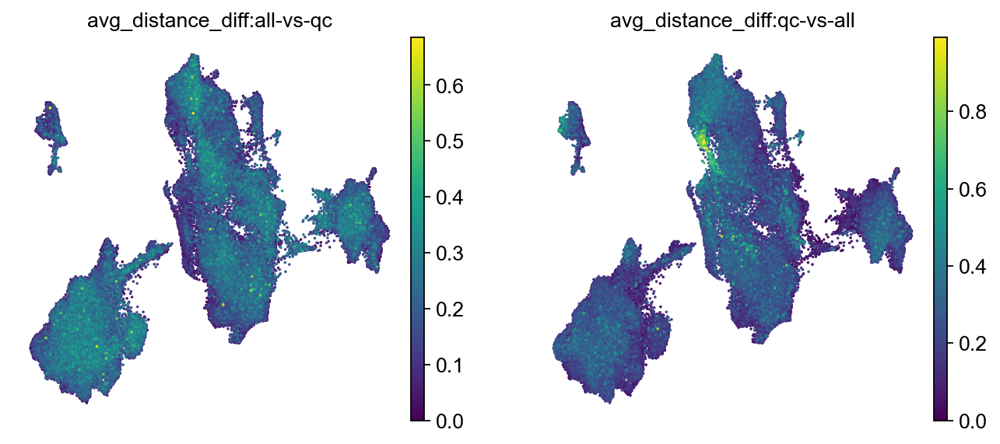

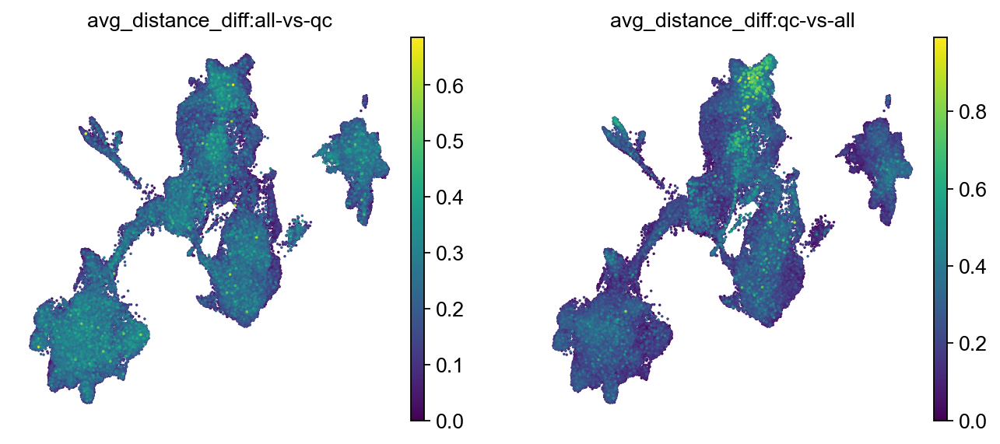

In [52]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color=gd_colors,
    size=10,
)

sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=gd_colors,
    size=10,
)